<a href="https://colab.research.google.com/github/Yurii1960/goit-algo-hw-04/blob/main/Hw6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

import matplotlib.pyplot as plt
from google.colab import files
import pandas as pd
import numpy as np

import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
# Завантаження файлу
uploaded = files.upload()

Saving Housing.csv to Housing.csv


In [ ]:
df = pd.read_csv('Housing.csv')
df

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [ ]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df.size

7085

In [ ]:
df.dtypes

,0
price,int64
area,int64
bedrooms,int64
bathrooms,int64
stories,int64
mainroad,object
guestroom,object
basement,object
hotwaterheating,object
airconditioning,object


In [ ]:
def h(X,w):
  return np.dot(X,w)

def loss_function(X,y,w):
  return np.square(h(X,w)-y).sum()/(2*X.size)

def gradient_step(X,y,w,learning_rate):
  m=len(y)
  grad=(X.T@(h(X,w)-y))/m
  w-=learning_rate*grad
  return w

def gradient(X,y,learning_rate,num_iter,eps):
  ones=np.ones((X.shape[0],1))
  X=np.hstack((ones,X))
  w=np.zeros(X.shape[1])
  loss=loss_function(X,y,w)
  loss_history=[loss]
  for _ in range(num_iter):
    w=gradient_step(X,y,w,learning_rate)
    loss=loss_function(X,y,w)
    if abs(loss-loss_history[-1])<eps:
      loss_history.append(loss)
      break
    loss_history.append(loss)
  return w,loss_history


norm=df.copy()
columns=['price','area','bedrooms','bathrooms']
for column in columns:
  norm[column]=(df[column]-df[column].mean())/df[column].std()
X=norm[['area','bedrooms','bathrooms']].values
y=norm['price'].values
learning_rate=0.001
num_iter=10000
eps=0.00000001
w,loss_history=gradient(X,y,learning_rate,num_iter,eps)
print('Gradient_Descent=',w.round(4))

ones=np.ones((X.shape[0],1))
X=np.hstack((ones,X))
w_analitic=np.linalg.inv(X.T@X)@X.T@y
print('Analitic_Solve=  ',w_analitic.round(4))








Gradient_Descent= [0.     0.4356 0.167  0.3677]
Analitic_Solve=   [0.     0.4395 0.1605 0.3723]


In [ ]:
X=norm[['area','bedrooms','bathrooms']].values
y=norm['price'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

ЛІНІЙНА РЕГРЕСІЯ

In [ ]:
#коефіцієнти моделі та метрики для тренувальних даних

lr_reg = LinearRegression().fit(X_train, y_train)
y_pred_lr = lr_reg.predict(X_test)
lr_mse = mean_squared_error(y_test, y_pred_lr)
lr_mae = mean_absolute_error(y_test, y_pred_lr)
lr_r2 = r2_score(y_test, y_pred_lr)

print('W0_train=', lr_reg.intercept_.round(4),'W1_train =', lr_reg.coef_[0].round(4),'W2_train =', lr_reg.coef_[1].round(4),'W3_train =', lr_reg.coef_[2].round(4))
print("MSE:", lr_mse,"MAE:", lr_mae,"R2:", lr_r2)


W0_train= -0.0023 W1_train = 0.4318 W2_train = 0.1504 W3_train = 0.3557
MSE: 0.6802397443902422 MAE: 0.6335173383180233 R2: 0.44736815556478493


In [ ]:
#коефіцієнти моделі та метрики для тестувальних даних

lr_reg = LinearRegression().fit(X_test, y_test)
y_pred_lr = lr_reg.predict(X_train)
lr_mse = mean_squared_error(y_train, y_pred_lr)
lr_mae = mean_absolute_error(y_train, y_pred_lr)
lr_r2 = r2_score(y_train, y_pred_lr)


print('W0_test=', lr_reg.intercept_.round(4),'W1_test =', lr_reg.coef_[0].round(4),'W2_test =', lr_reg.coef_[1].round(4),'W3_test =', lr_reg.coef_[2].round(4))
print("MSE:", round(lr_mse,4),"MAE:", round(lr_mae,4),"R2:",round(lr_r2,4))


W0_test= -0.0748 W1_test = 0.4605 W2_test = 0.196 W3_test = 0.3508
MSE: 0.4489 MAE: 0.4962 R2: 0.5001


1. Випадковий ліс

In [ ]:
# Розрахунки  метрик для тестових даних
rf_reg = RandomForestRegressor(random_state=42).fit(X_train, y_train)
y_pred_rf = rf_reg.predict(X_test)
rf_mse = mean_squared_error(y_test, y_pred_rf)
rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_r2 = r2_score(y_test, y_pred_rf)

print("MSE:", rf_mse,"MAE:", rf_mae,"R2:", rf_r2)


<class 'float'>
MSE: 0.7692461132906533 MAE: 0.6371939842844988 R2: 0.37505871728577556


2. Градієнтний бустінг

In [ ]:
# Розрахунки для тестових даних

gb_reg = GradientBoostingRegressor(random_state=42).fit(X_train, y_train)
y_pred_gr = gb_reg.predict(X_test)
gb_mse = mean_squared_error(y_test, y_pred_gr)
gb_mae = mean_absolute_error(y_test, y_pred_gr)
gb_r2 = r2_score(y_test, y_pred_gr)

print("MSE:", gb_mse,"MAE:", gb_mae,"R2:", gb_r2)


MSE: 0.696672557308629 MAE: 0.6277993542231813 R2: 0.4340180157247683


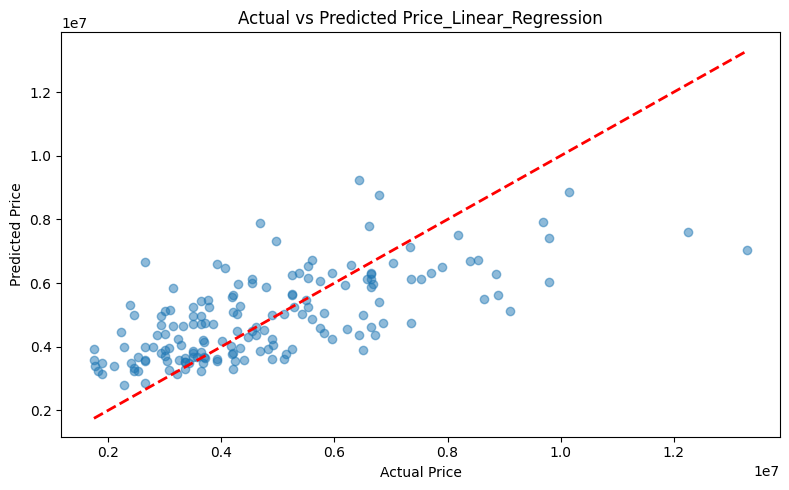

In [ ]:
lr_reg = LinearRegression().fit(X_train, y_train)
y_pred_lr = lr_reg.predict(X_test)
plt.figure(figsize=(8, 5))
y_test_real=y_test*df['price'].std()+df['price'].mean()
y_pred_lr_real= y_pred_lr*df['price'].std()+df['price'].mean()
plt.scatter(y_test_real, y_pred_lr_real, alpha=0.5)
plt.plot([y_test_real.min(), y_test_real.max()], [y_test_real.min(), y_test_real.max()], 'r--', lw=2)
plt.title('Actual vs Predicted Price_Linear_Regression')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.tight_layout()
plt.show()

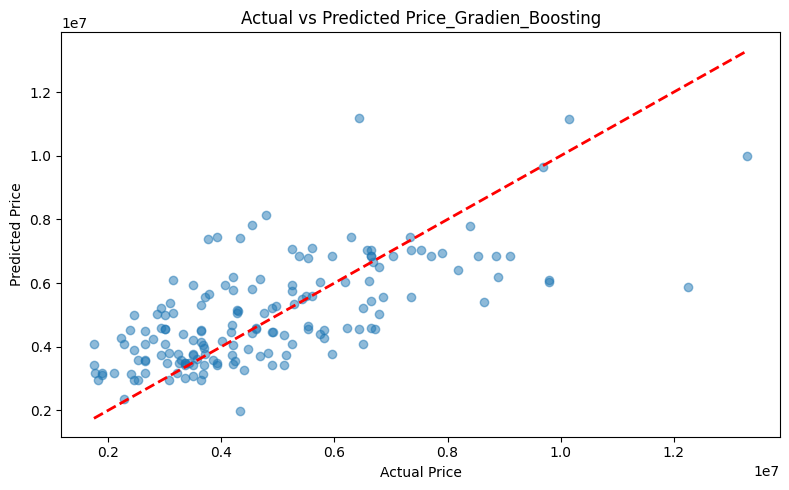

In [ ]:
plt.figure(figsize=(8, 5))
y_test_real=y_test*df['price'].std()+df['price'].mean()
y_pred_gr_real= y_pred_gr*df['price'].std()+df['price'].mean()
plt.scatter(y_test_real, y_pred_gr_real, alpha=0.5)
plt.plot([y_test_real.min(), y_test_real.max()], [y_test_real.min(), y_test_real.max()], 'r--', lw=2)
plt.title('Actual vs Predicted Price_Gradien_Boosting')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.tight_layout()
plt.show()


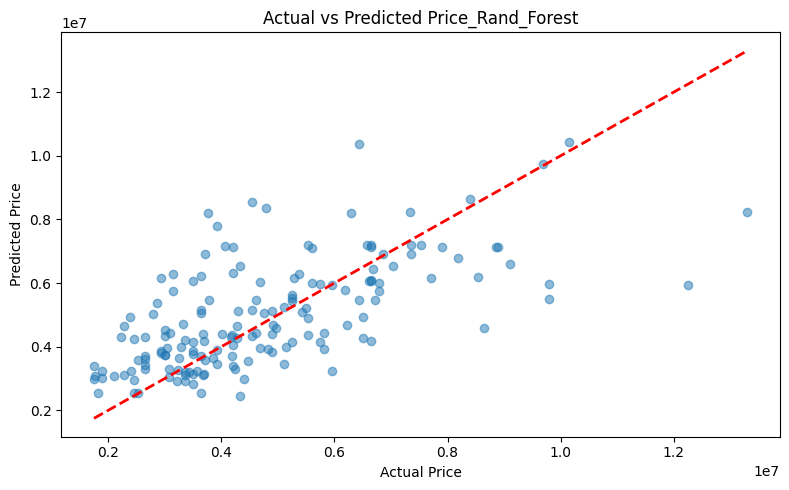

In [ ]:
plt.figure(figsize=(8, 5))
y_pred_rf_real= y_pred_rf*df['price'].std()+df['price'].mean()
plt.scatter(y_test_real, y_pred_rf_real, alpha=0.5)
plt.plot([y_test_real.min(), y_test_real.max()], [y_test_real.min(), y_test_real.max()], 'r--', lw=2)
plt.title('Actual vs Predicted Price_Rand_Forest')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.tight_layout()
plt.show()


ВИСНОВКИ:1. Поділ даних в пропорції 70 тренувальних і 30 тестувальних приводить до близьких кофіцієнтів лінії регресії і тому краще використовувати test_size=0.3
   2. Всі розглянуті моделі однково "погані". Тобто не дають хороших коефіцієнтів детермінації.
3. Для покращення моделі можливо треба розширити список властивостей